In [2]:
#imports
# Standard libraries
import math                                                 # Mathematical functions (sin, cos, sqrt, etc.)
import random                                               # Random number generation and sampling
import sys                                                  # System-specific parameters and functions (e.g. exit, argv)
import os                                                   # Operating system interfaces (file paths, environment variables)

# Scientific computing and data handling
import numpy as np                                          # Numerical computing (arrays, linear algebra, etc.)
import matplotlib.pyplot as plt                             # Plotting and visualization
import csv                                                  # Reading and writing CSV files
import pandas as pd                                         # Data manipulation and analysis (DataFrames, Series)

# Python type hints and data structures
from dataclasses import dataclass                           # Decorator for creating classes with auto-generated special methods
from typing import Tuple                                    # Type hints for tuples and other complex types

# PyTorch: Deep learning framework
import torch                                                # Tensors and neural network building blocks
from torch import nn                                        # Neural network layers and loss functions
from torch.utils.data import Dataset, DataLoader            # Dataset and batch loading utilities

# PyTorch Lightning: High-level interface for PyTorch
import lightning as L                                       # Core Lightning module
from lightning.pytorch import Trainer                       # Training loop management
from lightning.pytorch.callbacks import (                   # Training utilities:
    EarlyStopping,                                          # Stop training when a metric stops improving
    ModelCheckpoint,                                        # Save the best model during training
    TQDMProgressBar                                         # Progress bar for training
)
from lightning.pytorch.loggers import TensorBoardLogger     # Logging to TensorBoard

# Metrics for model evaluation
import torchmetrics as tm                                   # Collection of metrics (RMSE, Accuracy, etc.) for PyTorch


device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(device)

Te = 0.05

cpu


In [24]:
def load_csv_to_tensors(input_csv: str, target_csv: str, input_size: int = 1, output_size: int = 1, has_header: bool = False):
    """
    Load two CSV files (inputs U and outputs Y) and convert them into PyTorch tensors.
    
    Assumptions:
      - Each row in the CSV represents a full sequence (trajectory)
      - Columns represent time steps in a 'wide' format
      - input_size and output_size define the number of features per time step
    
    Args:
        input_csv (str): Path to the CSV file containing input sequences (U)
        target_csv (str): Path to the CSV file containing output sequences (Y)
        input_size (int): Number of input features per time step
        output_size (int): Number of output features per time step
        has_header (bool): True if the CSV files include a header row
    
    Returns:
        X (torch.Tensor): Input tensor of shape (N, T, input_size)
        Y (torch.Tensor): Output tensor of shape (N, T, output_size)
    """
    
    # Determine header option for pandas
    header = 0 if has_header else None
    
    # Load CSV files into NumPy arrays (float32 for PyTorch compatibility)
    U = pd.read_csv(input_csv, header=header).values.astype('float32')
    Y = pd.read_csv(target_csv, header=header).values.astype('float32')
    
    # Check that both files have the same number of sequences
    if U.shape[0] != Y.shape[0]:
        raise ValueError(f"Number of sequences differs: U has {U.shape[0]}, Y has {Y.shape[0]}.")
    
    # Helper function to reshape from (N, T*dim) to (N, T, dim)
    def reshape(arr, dim):
        if arr.shape[1] % dim != 0:
            raise ValueError(f"Number of columns {arr.shape[1]} is not divisible by dim={dim}.")
        T = arr.shape[1] // dim
        return arr.reshape(arr.shape[0], T, dim)
    
    # Reshape both input and output arrays
    U = reshape(U, input_size)
    Y = reshape(Y, output_size)
    
    # Convert to PyTorch tensors
    X = torch.tensor(U, dtype=torch.float32)
    Y = torch.tensor(Y, dtype=torch.float32)
    
    return X, Y

# Lightning Data Base ----------------------------------------------------------------------------------------------------------------------------------

class dataModule(L.LightningDataModule):
    """
    LightningDataModule for handling dataset splitting and loading.
    This class prepares the data for training, validation, and testing in PyTorch Lightning.
    """
    def __init__(self, data_u, data_y, batch_size=32):
        """
        Initialize the data module with input and output data.

        Args:
            data_u (torch.Tensor): Input data tensor.
            data_y (torch.Tensor): Output data tensor.
            batch_size (int, optional): Number of samples per batch. Defaults to 32.
        """
        super().__init__()
        self.batch_size = batch_size
        self.N = data_u.shape[0]  # Total number of samples
        self.data_u = data_u  # Store input data
        self.data_y = data_y  # Store output data
    
    def normalize(self, data, mean, std):
        # return data
        return (data - mean) / std
        
    def setup(self, stage=None):
        """
        Split the dataset into training, validation, and test sets.

        Args:
            stage (str, optional): Stage of the training process (fit, validate, test, predict). Defaults to None.
        """
        self.N_train =  int(self.N*0.7) # 70% of data for training
        self.N_val =   int(self.N*0.15) # 15% of data for validation
        self.N_test =   int(self.N*0.15) # Remaining 15% for testing
        
        self.u_mean =  self.data_u[:self.N_train].mean()
        self.u_std =  self.data_u[:self.N_train].std()
        
        self.y_mean =  self.data_y[:self.N_train].mean()
        self.y_std =  self.data_y[:self.N_train].std()
        
        # Create TensorDatasets for each split
        # Train set
        self.train_dataset = torch.utils.data.TensorDataset(
            self.normalize(self.data_u[:self.N_train], self.u_mean, self.u_std), self.normalize(self.data_y[:self.N_train], self.y_mean, self.y_std)
        )

        # Vaidation set
        self.val_dataset = torch.utils.data.TensorDataset(
            self.normalize(self.data_u[self.N_train:self.N_train + self.N_val], self.u_mean, self.u_std), self.normalize(self.data_y[self.N_train:self.N_train + self.N_val], self.y_mean, self.y_std)
        )
        
        # Test set
        self.test_dataset = torch.utils.data.TensorDataset(
            self.normalize(self.data_u[self.N_train + self.N_val:self.N_train + self.N_test + self.N_val], self.u_mean, self.u_std), self.normalize(self.data_y[self.N_train+self.N_val:self.N_train + self.N_test + self.N_val], self.y_mean, self.y_std)
        )

    def train_dataloader(self):
        """
        Return the DataLoader for the training set.

        Returns:
            DataLoader: Training data loader with shuffling.
        """
        return DataLoader(self.train_dataset, batch_size=self.batch_size, shuffle=True)

    def val_dataloader(self):
        """
        Return the DataLoader for the validation set.

        Returns:
            DataLoader: Validation data loader without shuffling.
        """
        return DataLoader(self.val_dataset, batch_size=self.batch_size, shuffle=False)

    def test_dataloader(self):
        """
        Return the DataLoader for the test set.

        Returns:
            DataLoader: Test data loader without shuffling.
        """
        return DataLoader(self.test_dataset, batch_size=self.batch_size, shuffle=False)

# NN definition -----------------------------------------------------------------------------------------------------------------------------------------------
class model_nn(L.LightningModule):
    """
    Sequential neural network model (RNN/LSTM/GRU) for aligned sequence-to-sequence mapping U->Y.
    """
    def __init__(
        self,
        input_size: int =   1,
        output_size: int =  1,
        rnn_type: str = "RNN",  # "RNN", "LSTM", "GRU"
        hidden_size: int =  16,
        num_layers: int =  1,
        dropout: float = 0.0,
        lr: float = 1e-3,
        weight_decay: float = 0.0,
        bidirectional: bool = False,
    ):
        """
        Initialize the model with the specified architecture and hyperparameters.

        Args:
            input_size (int): Number of input features.
            output_size (int): Number of output features.
            rnn_type (str): Type of recurrent layer ("RNN", "LSTM", "GRU").
            hidden_size (int): Number of hidden units in the RNN layer.
            num_layers (int): Number of recurrent layers.
            dropout (float): Dropout probability between RNN layers.
            lr (float): Learning rate for the optimizer.
            weight_decay (float): Weight decay (L2 penalty) for the optimizer.
            bidirectional (bool): If True, becomes a bidirectional RNN.
        """
        super().__init__()
        self.save_hyperparameters()
        # Select and initialize the RNN type
        if rnn_type.upper() == "LSTM":
            self.rnn = nn.LSTM(
                input_size=input_size,
                hidden_size=hidden_size,
                num_layers=num_layers,
                dropout=dropout if num_layers > 1 else 0.0,
                bidirectional=bidirectional,
                batch_first=True
            )
        elif rnn_type.upper() == "GRU":
            self.rnn = nn.GRU(
                input_size=input_size,
                hidden_size=hidden_size,
                num_layers=num_layers,
                dropout=dropout if num_layers > 1 else 0.0,
                bidirectional=bidirectional,
                batch_first=True
            )
        elif rnn_type.upper() == "RNN":
            self.rnn = nn.RNN(
                input_size=input_size,
                hidden_size=hidden_size,
                num_layers=num_layers,
                nonlinearity='tanh',
                dropout=dropout if num_layers > 1 else 0.0,
                bidirectional=bidirectional,
                batch_first=True
            )
        else:
            raise ValueError("rnn_type must be one of {'RNN','LSTM','GRU'}")
        # Linear head for output projection
        d = 2 if bidirectional else 1
        self.head = nn.Linear(d * hidden_size, output_size)
        self.loss_fn = nn.MSELoss()  # Mean squared error loss

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Forward pass of the model.

        Args:
            x (torch.Tensor): Input tensor of shape (batch, T, input_size).

        Returns:
            torch.Tensor: Output tensor of shape (batch, T, output_size).
        """
        h, _ = self.rnn(x)              # h: (batch, T, d*hidden_size)
        y = self.head(h)                # y: (batch, T, output_size)
        return y

    def training_step(self, batch, batch_idx):
        """
        Training step: forward pass, loss computation, and logging.

        Args:
            batch: Tuple of (input, target) tensors.
            batch_idx: Index of the current batch.

        Returns:
            torch.Tensor: Computed loss.
        """
        x, y = batch
        y_hat = self(x)
        loss = self.loss_fn(y_hat, y)
        self.log("train_loss", loss, on_step=True, on_epoch=True, prog_bar=True)
        return loss

    def validation_step(self, batch, batch_idx):
        """
        Validation step: forward pass, loss computation, and logging.

        Args:
            batch: Tuple of (input, target) tensors.
            batch_idx: Index of the current batch.
        """
        x, y = batch
        y_hat = self(x)
        loss = self.loss_fn(y_hat, y)
        self.log("val_loss", loss, on_epoch=True, prog_bar=True)

    def test_step(self, batch, batch_idx):
        """
        Test step: forward pass, loss computation, and logging.

        Args:
            batch: Tuple of (input, target) tensors.
            batch_idx: Index of the current batch.
        """
        x, y = batch
        y_hat = self(x)
        loss = self.loss_fn(y_hat, y)
        self.log("test_loss", loss, on_epoch=True, prog_bar=True)

    def configure_optimizers(self):
        """
        Configure the optimizer for training.

        Returns:
            torch.optim.Optimizer: Adam optimizer instance.
        """
        opt = torch.optim.Adam(
            self.parameters(),
            lr=self.hparams.lr,
            weight_decay=self.hparams.weight_decay
        )
        return opt

# Train function def ---------------------------------------------------------------------------------------------------------------------------------------------------------

def train_run(data_u, data_y, model_save_name, epoch_max=10, nb_train=1, patience_EarlyStopping=200, refresh_rate_brogress_bar=10, batch_size = 32):
    """
    Train a model multiple times with the given data and save the results.

    Args:
        data_u (np.ndarray): Input data for training.
        data_y (np.ndarray): Output data for training.
        model_save_name (str): Name of the directory to save model logs and checkpoints.
        epoch_max (int, optional): Maximum number of training epochs. Defaults to 10.
        nb_train (int, optional): Number of training runs. Defaults to 1.
        patience_EarlyStopping (int, optional): Patience for early stopping. Defaults to 200.
        refresh_rate_brogress_bar (int, optional): Refresh rate for the progress bar. Defaults to 10.
    """
    for index_train in range(nb_train):
        print("Train ", index_train)
        # Initialize the data module with input and output data
        data_module = dataModule(data_u, data_y, batch_size=batch_size)

        # Initialize the model
        model = model_nn()

        # Set up TensorBoard logger to save training logs
        logger = L.pytorch.loggers.TensorBoardLogger(model_save_name)

        # Early stopping callback to halt training if validation loss does not improve
        early_stopping_callback = EarlyStopping(
            monitor='val_loss',
            patience=patience_EarlyStopping,
            mode='min'
        )

        # Model checkpoint callback to save the best model based on validation loss
        checkpoint_callback = ModelCheckpoint(
            monitor='val_loss',  # Metric to monitor for saving the best model
            dirpath=logger.log_dir,  # Directory to save the model checkpoints
            filename='model',  # Filename format for saved models
            save_top_k=1,  # Save only the best model
            mode='min',  # Save the model with the minimum validation loss
        )

        # Initialize the trainer with callbacks and logger
        trainer = L.Trainer(
            max_epochs=epoch_max,
            logger=logger,
            callbacks=[
                early_stopping_callback,
                checkpoint_callback,
                TQDMProgressBar(refresh_rate=refresh_rate_brogress_bar)
            ]
        )

        # Train the model
        trainer.fit(model, data_module)

        # Test the model after training
        trainer.test(model, datamodule=data_module)

        # Print the logger information
        print(logger)
    return data_module.u_mean, data_module.y_mean, data_module.u_std, data_module.y_std

In [4]:
# Define the dimensions of input and output for the model
input_size =  1                             # Number of input features per time step
output_size = 1                             # Number of output features per time step
has_header = False                          # Flag indicating whether the CSV files have a header row

csv_u = 'bdd_in_mat_05_postfiltre.csv'               # CSV filename for input data
csv_y = 'bdd_out_mat_05_postfiltre.csv'              # CSV filename for output data

# Load the input and output data from CSV files into PyTorch tensors
tensor_u, tensor_y = load_csv_to_tensors(
    csv_u,                                  # Path to the input CSV file
    csv_y,                                  # Path to the output CSV file
    input_size,                             # Number of input features
    output_size,                            # Number of output features
    has_header                              # Whether the CSV files have a header row
)

# Training ----------------------------------------------------------------------------------------------------------------------------------------

# Define the name for saving the model and logs
model_save_name = 'model_rnn'               # Directory name where model checkpoints and logs will be saved

# Run the training process with the specified parameters
u_mean, y_mean, u_std, y_std = train_run(
    tensor_u,                               # Input data tensor
    tensor_y,                               # Output data tensor
    model_save_name,                        # Name for saving the model
    epoch_max=100,                          # Maximum number of training epochs
    nb_train=1,                             # Number of training runs
    patience_EarlyStopping=200,             # Number of epochs to wait before early stopping if no improvement
    refresh_rate_brogress_bar=10,           # Refresh rate for the progress bar (in batches)
    batch_size = 32
)

print(u_mean, y_mean, u_std, y_std)


GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/home/salade/Téléchargements/Student_folder/Student_folder/dronecontroler/.venv/lib/python3.14/site-packages/lightning/pytorch/callbacks/model_checkpoint.py:881: Checkpoint directory /home/salade/Téléchargements/Student_folder/Student_folder/dronecontroler/model_rnn/lightning_logs/version_0 exists and is not empty.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name    | Type    | Params | Mode  | FLOPs
----------------------------------------------------
0 | rnn     | RNN     | 304    | train | 0    
1 | head    | Linear  | 17     | train | 0    
2 | loss_fn | MSELoss | 0      | train | 0    
----------------------------------------------------
321       Trainable params
0         Non-

Train  0
                                                                            

c:\Users\cs_fondation\Downloads\04-td-deep-rl\td4-deep-rl\.venv\Lib\site-packages\lightning\pytorch\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
c:\Users\cs_fondation\Downloads\04-td-deep-rl\td4-deep-rl\.venv\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=7` in the `DataLoader` to improve performance.
c:\Users\cs_fondation\Downloads\04-td-deep-rl\td4-deep-rl\.venv\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=7` in the `DataLoader` to improve performance.


Epoch 99: 100%|██████████| 66/66 [00:00<00:00, 170.49it/s, v_num=0, train_loss_step=0.000418, val_loss=0.000599, train_loss_epoch=0.107]


Detected KeyboardInterrupt, attempting graceful shutdown ...


Epoch 99: 100%|██████████| 66/66 [00:00<00:00, 169.37it/s, v_num=0, train_loss_step=0.000418, val_loss=0.000599, train_loss_epoch=0.107]

LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
/home/salade/Téléchargements/Student_folder/Student_folder/dronecontroler/.venv/lib/python3.14/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'test_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=7` in the `DataLoader` to improve performance.



Testing DataLoader 0: 100%|██████████| 15/15 [00:00<00:00, 576.02it/s]
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
       Test metric             DataLoader 0
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
        test_loss          0.0006066780188120902
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
tensor(-0.0023) tensor(-9.7708) tensor(0.5731) tensor(12.5953)


model_nn(
  (rnn): RNN(1, 16, batch_first=True)
  (head): Linear(in_features=16, out_features=1, bias=True)
  (loss_fn): MSELoss()
)
rnn.weight_ih_l0 torch.Size([16, 1])
rnn.weight_hh_l0 torch.Size([16, 16])
rnn.bias_ih_l0 torch.Size([16])
rnn.bias_hh_l0 torch.Size([16])
head.weight torch.Size([1, 16])
head.bias torch.Size([1])


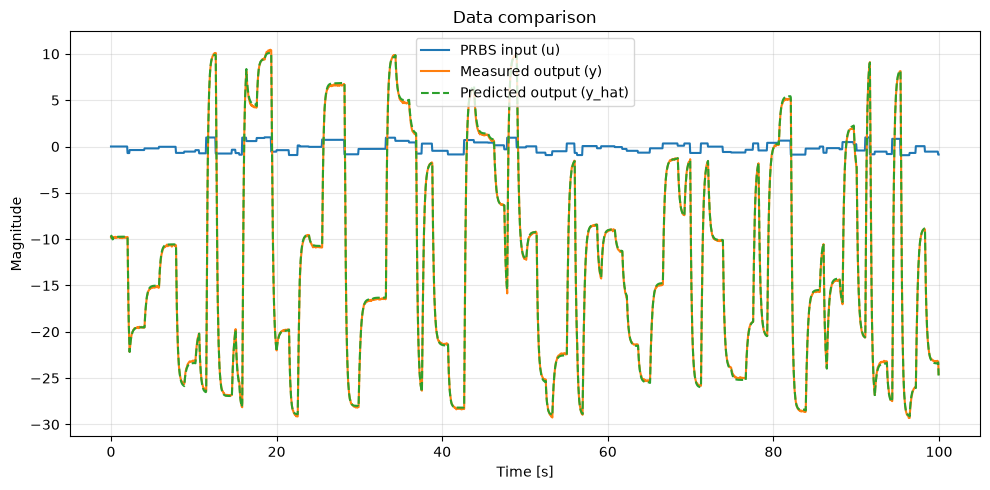

In [5]:
# Display results ----------------------------------------------------------------------------------------------------------------------------------

# Load the trained model (adjust the path as needed)
model_path = 'model_rnn/lightning_logs/version_0/model.ckpt'        # Path to the trained model checkpoint       # To be completed
model = model_nn.load_from_checkpoint(model_path)                                           # Load the model from checkpoint
model.to(device)                                                                            # Move the model to the appropriate device (CPU/GPU)
model.eval()                                                                                # Set the model to evaluation mode
print(model)                                                                                # Print model architecture and parameters

# Display detailed information about model parameters
for name, param in model.named_parameters():
    print(name, param.shape)                                                                # Print parameter names and shapes

# Select a test sequence (here, the last one)
u_test = tensor_u[-1]                                                                       # Raw input: the model was trained without normalization. Last input sequence from the dataset
y_test = tensor_y[-1]                                                                      # Corresponding output sequence

# Add batch dimension and move to device if needed
u_test_in = (u_test.unsqueeze(0).to(device) - u_mean.item()) / u_std.item()                                              # Reshape to (1, T, 1) and move to device

# Model prediction (no gradient computation)
with torch.no_grad():
    y_pred = (model(u_test_in).squeeze(0).squeeze(-1).cpu().numpy()) * y_std.item() + y_mean.item()     # Get predictions and convert to numpy
    # y_pred = (model(u_test_in).squeeze(0).squeeze(-1).cpu().numpy())  

# Prepare signals for plotting
u_plot = u_test.squeeze().numpy()                                                           # Remove extra dimensions for plotting
y_real = y_test.squeeze().numpy()                                                          # Remove extra dimensions for plotting
t = np.arange(len(u_plot)) * Te                                                             # Time array for x-axis (adjust Te if needed)

# Plot the input, real output, and predicted output
plt.figure(figsize=(10, 5))
plt.plot(t, u_plot, label="PRBS input (u)", color='tab:blue')                               # Plot input signal
plt.plot(t, y_real, label="Measured output (y)", color='tab:orange')                        # Plot real output
plt.plot(t, y_pred, label="Predicted output (y_hat)", color='tab:green', linestyle='--')    # Plot predicted output
plt.xlabel("Time [s]")                                                                      # X-axis label
plt.ylabel("Magnitude")                                                                     # Y-axis label
plt.title("Data comparison")                                                                # Plot title
plt.legend()                                                                                # Show legend
plt.grid(True, alpha=0.3)                                                                   # Add grid with transparency
plt.tight_layout()                                                                          # Adjust layout to prevent label cutoff
plt.show()
# Display the plot

In [ ]:
import torch

class MPC:
    def __init__(self, model_path, N=20):
        self.model = model_nn.load_from_checkpoint(model_path, map_location="cpu")
        self.model.eval()
        self.model.requires_grad_(False)

        self.u_m, self.u_s = u_mean.item(), u_std.item()
        self.y_m, self.y_s = y_mean.item(), y_std.item()

        self.N = N
        self.Q, self.R = 1, 1
        self.U = torch.zeros(N, requires_grad=True)                   
        self.h = torch.zeros(1, 1, 16)    
        self.opt = torch.optim.SGD([self.U], lr=1e-3)     

    def step_torch(self, h, u):
        x = u.reshape(1, 1, 1)
        _, h_new = self.model.rnn(x, h)
        y = self.model.head(h_new[-1])      
        return h_new, y

    def J(self, U, r, h0):
        h = h0
        cout = 0.0
        for k in range(self.N):
            h, y = self.step_torch(h, (U[k] - self.u_m) / self.u_s)
            cout += self.Q * (y * self.y_s + self.y_m - r[k]) ** 2 + self.R * U[k] ** 2
        return cout

    def step(self, r):
        for _ in range(50):
            self.opt.zero_grad()
            L = self.J(self.U, r, self.h)
            L.backward()
            self.opt.step()
            with torch.no_grad():
                self.U.clamp_(-1, 1)
        u = float(self.U[0])
        with torch.no_grad():
            self.h, _ = self.step_torch(self.h, torch.tensor((u - self.u_m) / self.u_s))
            self.U[:-1] = self.U[1:].clone()
        return u
    


In [ ]:
# Boucle principale MPC ------------------------------------------------------------------------------------------------------------------------------
# Le vrai drone est dans Simulink (UAV_model.slx) : ici le "système" est simulé par le RNN lui-même,
# avec son propre état h_sys, séparé de l'état interne du MPC.
from tqdm.auto import tqdm

mpc = MPC(model_path, N=20)

T_sim = 200                                         # nombre de pas simulés (T_sim * Te = 10 s)

# Consigne sur y (accélération verticale) : stationnaire -> montée -> stationnaire -> descente -> stationnaire
# Prolongée de N pas pour que la fenêtre de prédiction ne déborde pas à la fin
r_full = np.zeros(T_sim + mpc.N)
r_full[40:80] = 3.0
r_full[120:160] = -3.0

h_sys = torch.zeros(1, 1, 16)                       # état du système simulé
u_hist, y_hist = [], []

for t in tqdm(range(T_sim)):
    r_window = torch.tensor(r_full[t:t + mpc.N], dtype=torch.float32)
    u = mpc.step(r_window)                          # commande optimale (premier élément de U)

    # On applique u au système et on mesure y
    with torch.no_grad():
        h_sys, y_n = mpc.step_torch(h_sys, torch.tensor((u - mpc.u_m) / mpc.u_s))
    y = y_n.item() * mpc.y_s + mpc.y_m

    u_hist.append(u)
    y_hist.append(y)

# Affichage ------------------------------------------------------------------------------------------------------------------------------------------
t_axis = np.arange(T_sim) * Te

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

ax1.plot(t_axis, r_full[:T_sim], 'k--', label="Consigne r")
ax1.plot(t_axis, y_hist, color='tab:orange', label="Sortie y")
ax1.set_ylabel("Accélération verticale")
ax1.set_title("MPC sur le modèle RNN")
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.step(t_axis, u_hist, where='post', color='tab:blue', label="Commande u")
ax2.axhline(1, color='gray', linestyle=':', linewidth=1)
ax2.axhline(-1, color='gray', linestyle=':', linewidth=1)
ax2.set_xlabel("Temps [s]")
ax2.set_ylabel("u")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [ ]:
#Model export -------------------------------------------------------------------------------------------------------------------------------------

# Extracting weights
weight = model.state_dict()
weight_ih_l0 = weight['rnn.weight_ih_l0'].cpu().numpy()
weight_hh_l0 = weight['rnn.weight_hh_l0'].cpu().numpy()
bias_h = weight['rnn.bias_ih_l0'].cpu().numpy() + weight['rnn.bias_hh_l0'].cpu().numpy()
head_bias = weight['head.bias'].cpu().numpy()
head_weight = weight['head.weight'].cpu().numpy()

# Create the export directory if it does not exist
os.makedirs('export_NN', exist_ok=True)

# Function to write a numpy array in MATLAB format
def write_matlab_array(file_path, array):
    with open(file_path, 'w') as f:
        if array.ndim == 0:  # Scalar
            f.write(f"[{array}]")
        elif array.ndim == 1:  # 1D array
            f.write('[' + ' '.join(map(str, array)) + ']')
        else:  # 2D array
            mat_str = '[' + '; '.join([' '.join(map(str, row)) for row in array]) + ']'
            f.write(mat_str)

# Write each weight to a separate file
write_matlab_array('export_NN/weight_ih_l0.txt', weight_ih_l0)
write_matlab_array('export_NN/weight_hh_l0.txt', weight_hh_l0)
write_matlab_array('export_NN/bias_h.txt', bias_h)
write_matlab_array('export_NN/head_bias.txt', head_bias)
write_matlab_array('export_NN/head_weight.txt', head_weight)

print("Export completed! Files are in MATLAB format.")

Export completed! Files are in MATLAB format.
